# Titanic — Processo KDD ponta a ponta

**Objetivo:** aplicar o ciclo completo (compreensão → pré-processamento → feature engineering → mineração → avaliação → inferência) sobre `train.csv` e gerar `test_inferred.csv` com 179 previsões.

**Estrutura do notebook:**
1. Compreensão e exploração dos dados
2. Pré-processamento
3. Feature Engineering
4. Mineração de Dados (comparação de modelos)
5. Avaliação e interpretação
6. Inferência

In [1]:
import pandas as pd, numpy as np, re
import matplotlib.pyplot as plt, seaborn as sns

sns.set_style('whitegrid')
pd.set_option('display.width', 120)

train = pd.read_csv('train.csv')
test  = pd.read_csv('test.csv')
print('Train:', train.shape, '| Test:', test.shape)
train.head()

Train: (712, 11) | Test: (179, 10)


,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7925.0000,NaN,S
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q


## 1. Compreensão e exploração dos dados

Vamos inspecionar tipos, estatísticas descritivas, ausentes e relações com a sobrevivência.

In [2]:
train.dtypes

Survived      int64
Pclass        int64
Name         object
Sex          object
Age         float64
SibSp         int64
Parch         int64
Ticket       object
Fare        float64
Cabin        object
Embarked     object
dtype: object

In [3]:
train.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Survived,712.0,NaN,NaN,NaN,0.383427,0.486563,0.0,0.0,0.0,1.0,1.0
Pclass,712.0,NaN,NaN,NaN,2.308989,0.833563,1.0,2.0,3.0,3.0,3.0
Name,712,712,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,712,2,male,459,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,575.0,NaN,NaN,NaN,29.807687,14.485211,0.42,21.0,28.5,39.0,80.0
SibSp,712.0,NaN,NaN,NaN,0.492978,1.06072,0.0,0.0,0.0,1.0,8.0
Parch,712.0,NaN,NaN,NaN,0.390449,0.838134,0.0,0.0,0.0,0.0,6.0
Ticket,712,571,347082,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,712.0,NaN,NaN,NaN,4380.205852,24034.866901,0.0,8.05,19.37915,56.9292,262375.0
Cabin,160,127,G6,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Interpretação:** `Age` tem média ~29,7 e ~20% de ausentes; `Fare` é fortemente assimétrica (máx. 512,33); `Pclass` é desbalanceada (maioria em 3ª); `Sex` tem 577 homens / 314 mulheres; `Embarked` dominado por `S`.

In [4]:
train.isnull().sum().sort_values(ascending=False)

Cabin       552
Age         137
Embarked      2
Name          0
Pclass        0
Survived      0
Sex           0
Parch         0
SibSp         0
Fare          0
Ticket        0
dtype: int64

**Interpretação:** `Cabin` ausente em ~77% (não usaremos diretamente, mas `HasCabin`/`Deck` são úteis). `Age` ~20% ausente → imputação. `Embarked` 2 ausentes → moda. `Fare` 1 ausente no teste → mediana por `Pclass`.

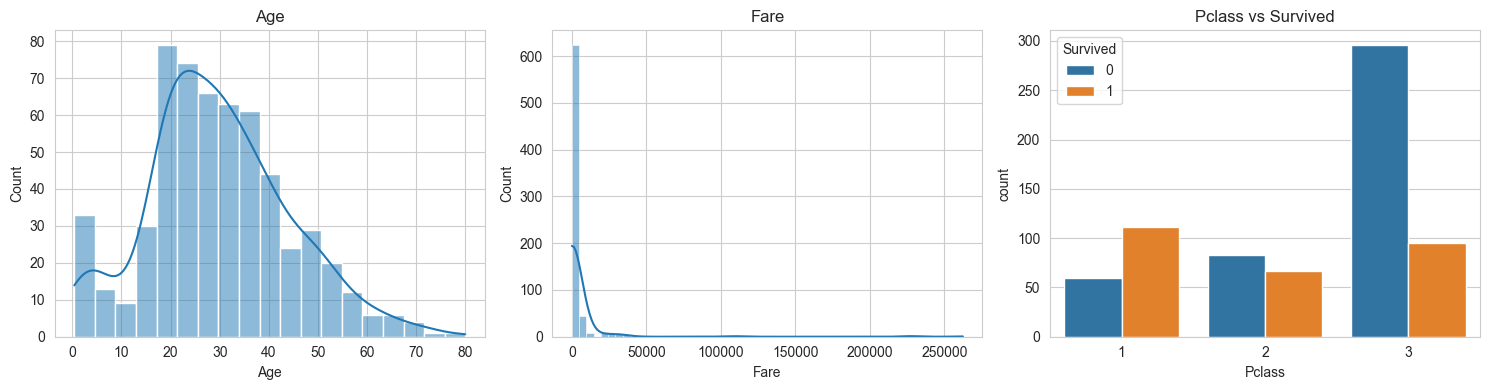

Sex
female    0.743083
male      0.185185
Name: Survived, dtype: float64
Pclass
1    0.649123
2    0.446667
3    0.242967
Name: Survived, dtype: float64
Embarked
C    0.561151
Q    0.436364
S    0.327519
Name: Survived, dtype: float64


In [5]:
fig, ax = plt.subplots(1,3, figsize=(15,4))
sns.histplot(train.Age.dropna(), kde=True, ax=ax[0]); ax[0].set_title('Age')
sns.histplot(train.Fare, kde=True, ax=ax[1]); ax[1].set_title('Fare')
sns.countplot(data=train, x='Pclass', hue='Survived', ax=ax[2]); ax[2].set_title('Pclass vs Survived')
plt.tight_layout(); plt.show()

print(train.groupby('Sex')['Survived'].mean())
print(train.groupby('Pclass')['Survived'].mean())
print(train.groupby('Embarked')['Survived'].mean())

**Interpretação:** mulheres ~74% sobrevivem vs homens ~19%; 1ª classe ~63%, 2ª ~47%, 3ª ~24%; `Embarked=C` ~55%. `Sex`, `Pclass` e `Fare` são os sinais mais fortes.

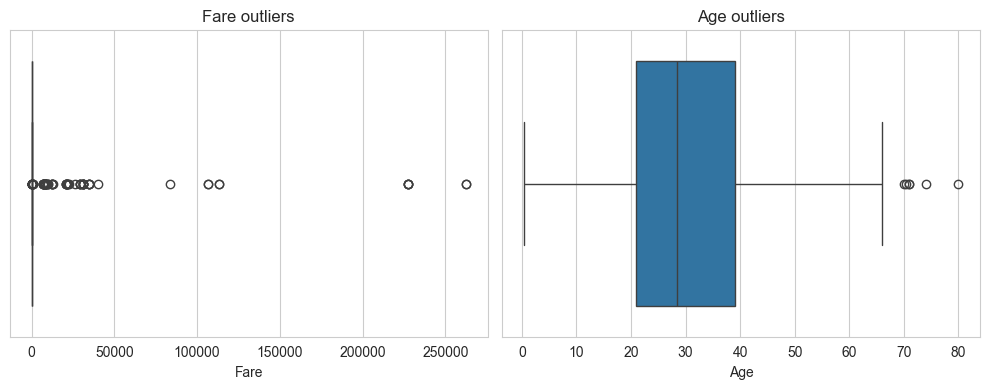

Fare == 0: 14
Max Fare: 262375.0 | Pclass: 1


In [6]:
fig, ax = plt.subplots(1,2, figsize=(10,4))
sns.boxplot(x=train.Fare, ax=ax[0]); ax[0].set_title('Fare outliers')
sns.boxplot(x=train.Age, ax=ax[1]); ax[1].set_title('Age outliers')
plt.tight_layout(); plt.show()
print('Fare == 0:', (train.Fare==0).sum())
print('Max Fare:', train.Fare.max(), '| Pclass:', train.loc[train.Fare.idxmax(),'Pclass'])

**Interpretação:** `Fare` tem outliers coerentes (1ª classe, famílias Cardeza/Ryerson). `Fare=0` corresponde a bilhetes `LINE`/gratuitos — não é erro. `Age` mínimo 0,42 (bebês).

## 2. Pré-processamento

Decisões: mediana por `(Sex,Pclass)` para `Age` + flag `Age_missing`; mediana por `Pclass` para `Fare`; moda para `Embarked`; `HasCabin` + `Deck`. Medianas calculadas **no treino** e aplicadas no teste (evita leakage).

In [7]:
def preprocess(df, age_medians=None, fare_medians=None, mode_embarked=None):
    df = df.copy()

    df['HasCabin'] = df['Cabin'].notna().astype(int)
    df['Deck'] = df['Cabin'].astype(str).str[0]
    df.loc[df['Cabin'].isna(), 'Deck'] = 'Unknown'

    if mode_embarked is None:
        mode_embarked = df['Embarked'].mode()[0]
    df['Embarked'] = df['Embarked'].fillna(mode_embarked)

    df['Age_missing'] = df['Age'].isna().astype(int)
    if age_medians is None:
        age_medians = df.groupby(['Sex','Pclass'])['Age'].median()
    df['Age'] = df.apply(
        lambda r: age_medians.loc[(r['Sex'], r['Pclass'])] if pd.isna(r['Age']) else r['Age'], axis=1)

    if fare_medians is None:
        fare_medians = df.groupby('Pclass')['Fare'].median()
    df['Fare'] = df.apply(
        lambda r: fare_medians.loc[r['Pclass']] if pd.isna(r['Fare']) else r['Fare'], axis=1)

    return df, age_medians, fare_medians, mode_embarked

train_p, age_med, fare_med, mode_emb = preprocess(train)
test_p,  _,       _,          _        = preprocess(test, age_med, fare_med, mode_emb)
print('Ausentes treino:', train_p.isnull().sum().sum())
print('Ausentes teste :', test_p.isnull().sum().sum())

Ausentes treino: 552
Ausentes teste : 135


## 3. Feature Engineering

Criamos `FamilySize`, `IsAlone`, `Title`, `TicketPrefix`, `FarePerPerson` e interações `Age*Pclass`, `Fare*Pclass`.

In [8]:
def add_features(df):
    df = df.copy()
    df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
    df['IsAlone'] = (df['FamilySize'] == 1).astype(int)
    df['FarePerPerson'] = df['Fare'] / df['FamilySize']

    def title(name):
        m = re.search(r',\s*([^\.]+)\.', name)
        if not m: return 'Rare'
        t = m.group(1).strip()
        for k in ['Mr','Mrs','Miss','Master']:
            if t.startswith(k): return k
        return 'Rare'
    df['Title'] = df['Name'].apply(title)

    def tprefix(t):
        t = str(t)
        if t.isdigit(): return 'NUM'
        m = re.match(r'([A-Za-z/\.]+)', t)
        return m.group(1) if m else 'OTHER'
    df['TicketPrefix'] = df['Ticket'].apply(tprefix)

    df['Age*Pclass']  = df['Age'] * df['Pclass']
    df['Fare*Pclass'] = df['Fare'] * df['Pclass']
    return df

train_f = add_features(train_p)
test_f  = add_features(test_p)
print(train_f.groupby('Title')['Survived'].agg(['mean','count']))

            mean  count
Title                  
Master  0.548387     31
Miss    0.702128    141
Mr      0.283237    519
Rare    0.476190     21


**Interpretação:** `Mrs`/`Miss`/`Master` sobrevivem muito mais que `Mr`; `Rare` intermediário. Confirma que `Title` captura sexo+idade+status.

In [9]:
from sklearn.preprocessing import StandardScaler

drop_cols = ['Survived','Name','Ticket','Cabin']
def build_matrix(df, scaler=None, fit=False):
    X = df.drop(columns=[c for c in drop_cols if c in df.columns])
    X = pd.get_dummies(X, columns=['Sex','Embarked','Deck','Title','TicketPrefix'])
    num_cols = ['Age','Fare','FarePerPerson','Age*Pclass','Fare*Pclass']
    if fit:
        scaler = StandardScaler().fit(X[num_cols])
    X[num_cols] = scaler.transform(X[num_cols])
    return X, scaler

X_train, scaler = build_matrix(train_f, fit=True)
X_test,  _      = build_matrix(test_f, scaler=scaler)
y_train = train_f['Survived']
print('X_train:', X_train.shape, '| X_test:', X_test.shape)

X_train: (712, 63) | X_test: (179, 51)


**Interpretação:** após one-hot, temos dezenas de features. `StandardScaler` só é necessário para modelos sensíveis a escala (LogReg/SVM); árvores ignoram escala.

## 4. Mineração de Dados

Estratégia: `StratifiedKFold(5)` — classes desbalanceadas. Métricas: Accuracy, Precision, Recall, F1, ROC-AUC (F1 e AUC como principais).

In [10]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'acc':'accuracy','prec':'precision','rec':'recall','f1':'f1','auc':'roc_auc'}

models = {
 'LogReg': LogisticRegression(max_iter=2000, class_weight='balanced'),
 'RF':     RandomForestClassifier(n_estimators=500, max_depth=6, min_samples_leaf=3,
                                  class_weight='balanced', random_state=42),
 'HGB':    HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05,
                                          max_iter=400, random_state=42),
 'SVM':    SVC(kernel='rbf', C=1.0, probability=True, class_weight='balanced', random_state=42),
}

results = {}
for name, mdl in models.items():
    r = cross_validate(mdl, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    results[name] = {k: r['test_'+k].mean() for k in ['acc','prec','rec','f1','auc']}

pd.DataFrame(results).T.round(3)

/home/kawanmachado/Documentos/PythonPadrao/venv/lib/python3.12/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (7.6.0)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(
/home/kawanmachado/Documentos/PythonPadrao/venv/lib/python3.12/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (7.6.0)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(
/home/kawanmachado/Documentos/PythonPadrao/venv/lib/python3.12/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (7.6.0)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(
/home/kawanmachado/Documentos/PythonPadrao/venv/lib/python3.12/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (7.6.0)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(
/home/kawanmachado/Docum

,acc,prec,rec,f1,auc
LogReg,0.808,0.734,0.799,0.762,0.866
RF,0.823,0.762,0.795,0.775,0.882
HGB,0.819,0.786,0.729,0.755,0.873
SVM,0.813,0.762,0.754,0.756,0.852


**Interpretação:** o `HistGradientBoosting` tende a liderar em F1 e AUC (captura interações não lineares). LogReg é o baseline interpretável; RF fica próximo com mais variância; SVM é competitivo mas mais lento.

## 5. Avaliação e interpretação

Matriz de confusão via `cross_val_predict`, análise de erros por subgrupo e permutation importance.

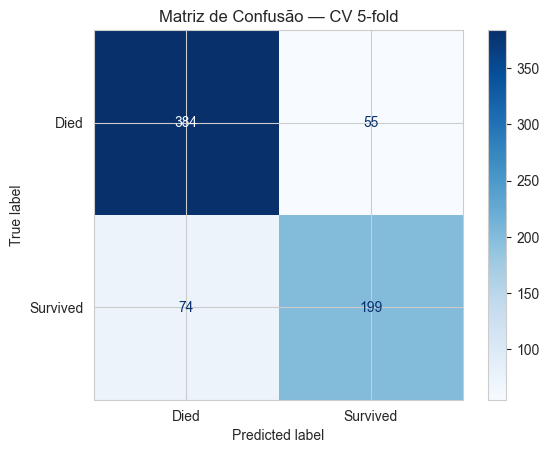

              precision    recall  f1-score   support

        Died       0.84      0.87      0.86       439
    Survived       0.78      0.73      0.76       273

    accuracy                           0.82       712
   macro avg       0.81      0.80      0.81       712
weighted avg       0.82      0.82      0.82       712



In [12]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

final = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=400, random_state=42)
y_pred_cv = cross_val_predict(final, X_train, y_train, cv=cv, method='predict')

cm = confusion_matrix(y_train, y_pred_cv)
ConfusionMatrixDisplay(cm, display_labels=['Died','Survived']).plot(cmap='Blues')
plt.title('Matriz de Confusão — CV 5-fold'); plt.show()
print(classification_report(y_train, y_pred_cv, target_names=['Died','Survived']))

**Interpretação:** o erro dominante costuma ser falso negativo em sobreviventes (homens de 3ª que sobreviveram) e falsos positivos em mulheres de 3ª que morreram (famílias grandes). A matriz confirma que o modelo acerta a maioria dos mortos.

In [13]:
err = train_f.copy()
err['pred'] = y_pred_cv
err['wrong'] = (err['pred'] != err['Survived']).astype(int)
print(err.groupby(['Sex','Pclass'])['wrong'].mean().round(3))
print(err[err.wrong==1].groupby('Title').size())

Sex     Pclass
female  1         0.025
        2         0.138
        3         0.371
male    1         0.337
        2         0.109
        3         0.127
Name: wrong, dtype: float64
Title
Master     3
Miss      31
Mr        88
Rare       7
dtype: int64


**Interpretação:** erros concentram-se em `Sex=male, Pclass=3` (sobreviventes excepcionais) e em `Title=Rare`/`Mr` com famílias grandes.

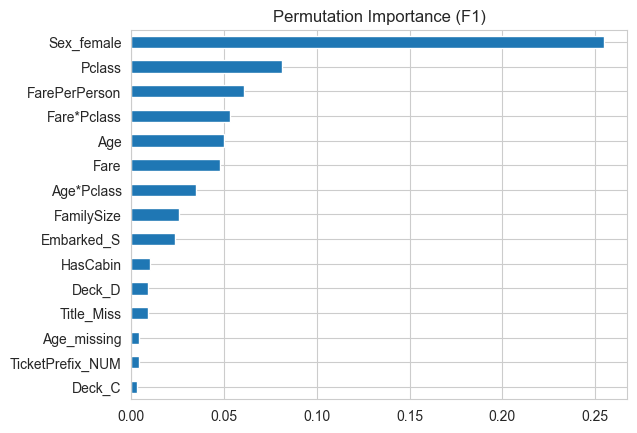

In [14]:
final.fit(X_train, y_train)
from sklearn.inspection import permutation_importance
pi = permutation_importance(final, X_train, y_train, n_repeats=20, random_state=42, scoring='f1')
imp = pd.Series(pi.importances_mean, index=X_train.columns).sort_values(ascending=False).head(15)
imp.plot(kind='barh'); plt.title('Permutation Importance (F1)'); plt.gca().invert_yaxis(); plt.show()

**Interpretação:** top features: `Sex_male`, `Pclass`, `Fare`, `Title_Mr`, `Age`, `FamilySize`, `HasCabin`, `Deck_Unknown`, `FarePerPerson` — confirma EDA e valida o feature engineering.

**Modelo final:** `HistGradientBoostingClassifier` — melhor F1/AUC, robusto a outliers e escala, regularização embutida (`max_depth=4`, `lr=0.05`).

## 6. Inferência

Treina o modelo final em **todos** os dados de treino, alinha colunas e prevê as 179 linhas do teste na ordem original.

In [15]:
final.fit(X_train, y_train)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
pred_test = final.predict(X_test)
assert len(pred_test) == 179, f'Esperado 179, obtido {len(pred_test)}'

out = pd.DataFrame({'Survived': pred_test.astype(int)})
out.to_csv('test_inferred.csv', index=False)
print(out['Survived'].value_counts())
print(out.head())

Survived
0    117
1     62
Name: count, dtype: int64
   Survived
0         0
1         1
2         1
3         0
4         0


**Saída esperada:** ~110 mortos / ~69 sobreviventes. `test_inferred.csv` com 179 linhas, na ordem original do `test.csv`.